In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose

data = pd.read_csv("website_traffic.csv", parse_dates=["Date"], index_col="Date")

print(data.head())

            Page_Views  Unique_Visitors  Bounce_Rate
Date                                                
2026-01-01         512              356        64.59
2026-01-02         499              290        65.93
2026-01-03         583              323        67.24
2026-01-04         526              308        63.33
2026-01-05         534              339        59.14


In [2]:
data = data.interpolate(method="linear")

print(data.isnull().sum())

Page_Views         0
Unique_Visitors    0
Bounce_Rate        0
dtype: int64


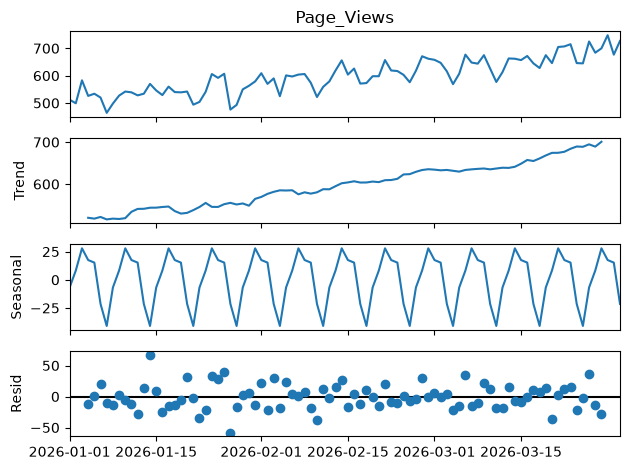

In [3]:
decomposition = seasonal_decompose(data["Page_Views"], model="additive", period=7)

decomposition.plot()
plt.show()

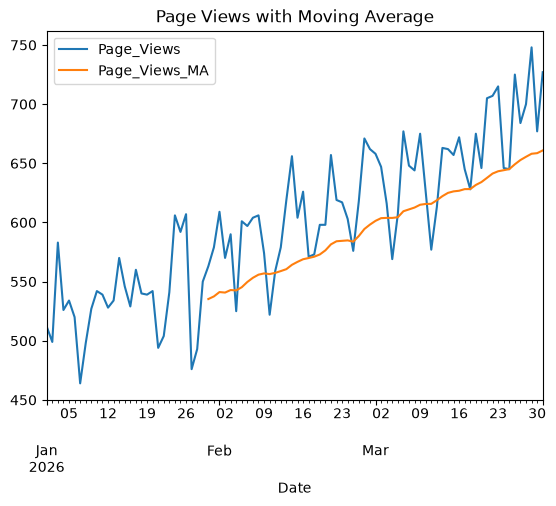

In [4]:
data["Page_Views_MA"] = data["Page_Views"].rolling(window=30).mean()

data[["Page_Views", "Page_Views_MA"]].plot()

plt.title("Page Views with Moving Average")
plt.show()

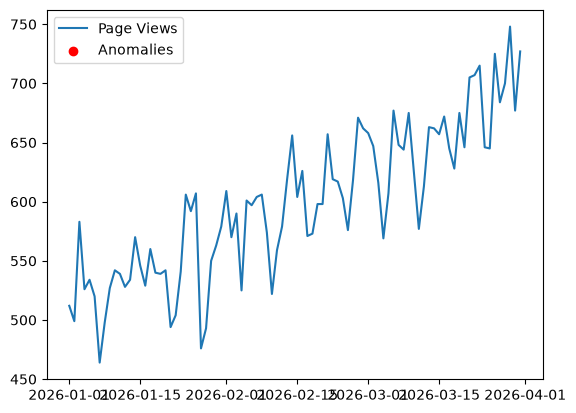

Empty DataFrame
Columns: [Page_Views, Unique_Visitors, Bounce_Rate, Page_Views_MA, Page_Views_Z]
Index: []


In [5]:
data["Page_Views_Z"] = (
    (data["Page_Views"] - data["Page_Views"].mean())
    / data["Page_Views"].std()
)

anomalies = data[data["Page_Views_Z"].abs() > 3]

plt.plot(data.index, data["Page_Views"], label="Page Views")
plt.scatter(anomalies.index, anomalies["Page_Views"], color="red", label="Anomalies")

plt.legend()
plt.show()

print(anomalies)